# 企业估值 Monte Carlo

本例按市场份额、销量、收入、现金流与 NPV 的关系生成经营情景，比较平均 NPV、正 NPV 概率和下行分位数，并核验贴现加权市场份额与 NPV=0 边界的对应关系。参数为教学设定，不代表真实企业。

[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-valuation) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/02-project-valuation-monte-carlo.zip)

本 Notebook 从头执行并保存输出；网页渲染不执行代码。


## 模型

市场总规模固定为 $Q_0$：

$$
Q_t=s_tQ_0,
$$

$$
Sales_t=pQ_t.
$$

市场份额：

$$
s_t=
\Lambda\left[
\alpha-\beta\log\left(\frac{p}{\bar p}\right)+\varepsilon_t
\right],
\qquad
\Lambda(x)=\frac{e^x}{1+e^x}.
$$

自由现金流：

$$
FCF_t=mSales_t-F.
$$

项目期限固定为：

$$
T=10.
$$

项目净现值：

$$
NPV=-I_0+\sum_{t=1}^{10}\frac{FCF_t}{(1+r)^t}.
$$

贴现率：

$$
5\%\le r\le12\%.
$$


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261001

# 教学参数
T = 10
Q0 = 1_000_000
p_ref = 100.0
alpha = -0.4
beta_price = 2.2
sigma_eps = 0.55

m = 0.28
F = 6_000_000
I0 = 35_000_000

a_r = 3.0
b_r = 4.0
r_min = 0.05
r_max = 0.12

B = 20_000


In [2]:

def logistic(x):
    return 1 / (1 + np.exp(-x))

def simulate_project(
    p,
    B=B,
    seed=SEED,
    Q0=Q0,
    alpha=alpha,
    beta_price=beta_price,
    p_ref=p_ref,
    sigma_eps=sigma_eps,
    m=m,
    F=F,
    I0=I0,
    T=T,
    a_r=a_r,
    b_r=b_r,
    r_min=r_min,
    r_max=r_max,
):
    rng = np.random.default_rng(seed)
    eps = rng.normal(0, sigma_eps, size=(B, T))
    share = logistic(
        alpha - beta_price * np.log(p / p_ref) + eps
    )
    quantity = share * Q0
    sales = p * quantity
    fcf = m * sales - F

    x_r = rng.beta(a_r, b_r, size=B)
    discount_rate = r_min + (r_max - r_min) * x_r

    years = np.arange(1, T + 1)
    df = (1 + discount_rate[:, None]) ** years
    npv = -I0 + np.sum(fcf / df, axis=1)

    # 贴现加权份额使用各情景自身的贴现率，不改变原 NPV 计算。
    discount_weight = (1 + discount_rate[:, None]) ** (-years)
    weighted_share = np.sum(share * discount_weight, axis=1) / discount_weight.sum(axis=1)

    return {
        "weighted_share": weighted_share,
        "npv": npv,
        "share": share,
        "avg_share": share.mean(axis=1),
        "quantity": quantity,
        "sales": sales,
        "fcf": fcf,
        "discount_rate": discount_rate,
    }

def annuity_factor(r, T=T):
    return (1 - (1 + r) ** (-T)) / r

def required_share_for_npv_zero(p, r):
    af = annuity_factor(r)
    annual_fcf_required = I0 / af
    annual_sales_contribution_required = annual_fcf_required + F
    return annual_sales_contribution_required / (m * p * Q0)



## 基准价格结果


In [3]:

base_p = 80.0
base = simulate_project(base_p)

summary = pd.Series({
    "Price": base_p,
    "Mean NPV (million)": base["npv"].mean() / 1e6,
    "Median NPV (million)": np.median(base["npv"]) / 1e6,
    "P(NPV > 0)": np.mean(base["npv"] > 0),
    "NPV 5% quantile (million)": np.quantile(base["npv"], 0.05) / 1e6,
    "NPV 95% quantile (million)": np.quantile(base["npv"], 0.95) / 1e6,
    "Mean market share": base["share"].mean(),
    "Mean discounted market share": base["weighted_share"].mean(),
    "Mean discount rate": base["discount_rate"].mean(),
})
summary


Price                           80.000000
Mean NPV (million)               3.188084
Median NPV (million)             3.122746
P(NPV > 0)                       0.683650
NPV 5% quantile (million)       -7.493066
NPV 95% quantile (million)      14.108453
Mean market share                0.521222
Mean discounted market share     0.521400
Mean discount rate               0.080055
dtype: float64

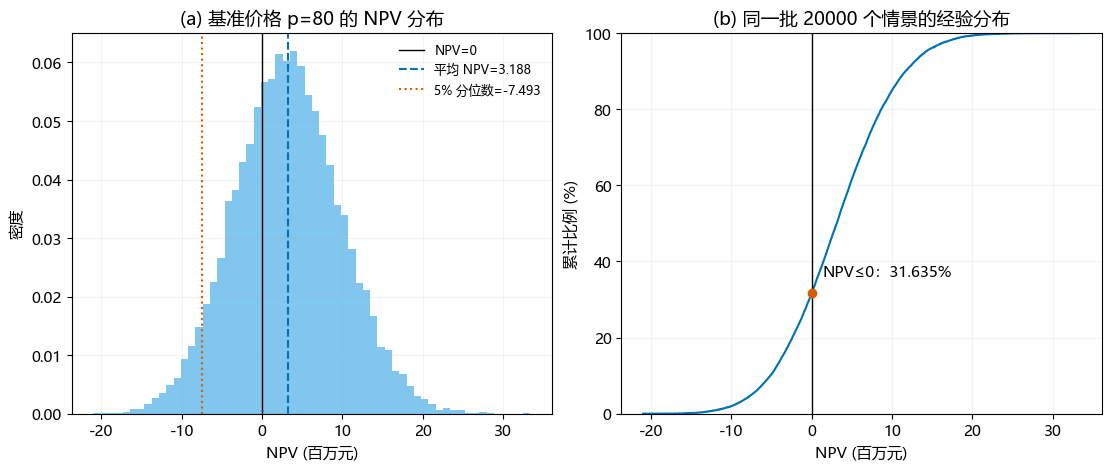

In [4]:
# BASELINE_FIGURE
plt.rcParams.update({'font.family': 'Microsoft YaHei', 'font.size': 11,
                     'axes.unicode_minus': False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
values = base['npv'] / 1e6
axes[0].hist(values, bins=60, density=True, color='#56B4E9', alpha=.75)
axes[0].axvline(0, color='black', linewidth=1, label='NPV=0')
axes[0].axvline(values.mean(), color='#0072B2', linestyle='--',
                label=f'平均 NPV={values.mean():.3f}')
axes[0].axvline(np.quantile(values, .05), color='#D55E00', linestyle=':',
                label=f'5% 分位数={np.quantile(values, .05):.3f}')
axes[0].set(title='(a) 基准价格 p=80 的 NPV 分布', xlabel='NPV (百万元)', ylabel='密度')
axes[0].legend(frameon=False, fontsize=9)
sorted_values = np.sort(values)
probabilities = np.arange(1, B + 1) / B
axes[1].step(sorted_values, probabilities * 100, where='post', color='#0072B2')
nonpositive = np.mean(values <= 0) * 100
axes[1].axvline(0, color='black', linewidth=1)
axes[1].scatter([0], [nonpositive], color='#D55E00', zorder=3)
axes[1].annotate(f'NPV≤0：{nonpositive:.3f}%', xy=(0, nonpositive),
                 xytext=(8, 12), textcoords='offset points')
axes[1].set(title='(b) 同一批 20000 个情景的经验分布',
            xlabel='NPV (百万元)', ylabel='累计比例 (%)', ylim=(0, 100))
for axis in axes:
    axis.grid(alpha=.15)
plt.show()

## 不同价格下的决策结果

候选价格从 55 到 160，步长为 5。各价格使用相同种子，从而共用同一组需求冲击和贴现率。比较的是不同价格下的完整 NPV 分布，不是为每个价格重新设定市场条件。表中新增 5% 分位数，和平均 NPV、正 NPV 比例一起作为比较指标。

In [5]:

price_grid = np.arange(55, 161, 5)

rows = []
for p in price_grid:
    result = simulate_project(p)
    rows.append({
        "price": p,
        "mean_npv_million": result["npv"].mean() / 1e6,
        "median_npv_million": np.median(result["npv"]) / 1e6,
        "prob_positive": np.mean(result["npv"] > 0),
        "npv_5pct_million": np.quantile(result["npv"], 0.05) / 1e6,
        "mean_share": result["share"].mean(),
    })

price_results = pd.DataFrame(rows)
price_results


,price,mean_npv_million,median_npv_million,prob_positive,npv_5pct_million,mean_share
0,55,-2.619689,-2.620367,0.25885,-9.288763,0.702153
1,60,-0.411728,-0.424316,0.46425,-8.002956,0.663165
2,65,1.201970,1.180067,0.59120,-7.269648,0.625320
3,70,2.294102,2.255193,0.65585,-6.984696,0.588925
4,75,2.934453,2.886355,0.68225,-7.074938,0.554185
5,80,3.188084,3.122746,0.68365,-7.493066,0.521222
6,85,3.114320,3.024545,0.66845,-8.159387,0.490092
7,90,2.766341,2.635134,0.64180,-8.994470,0.460803
8,95,2.191171,2.014173,0.60790,-9.976331,0.433329
9,100,1.429937,1.243946,0.56340,-11.085646,0.407615


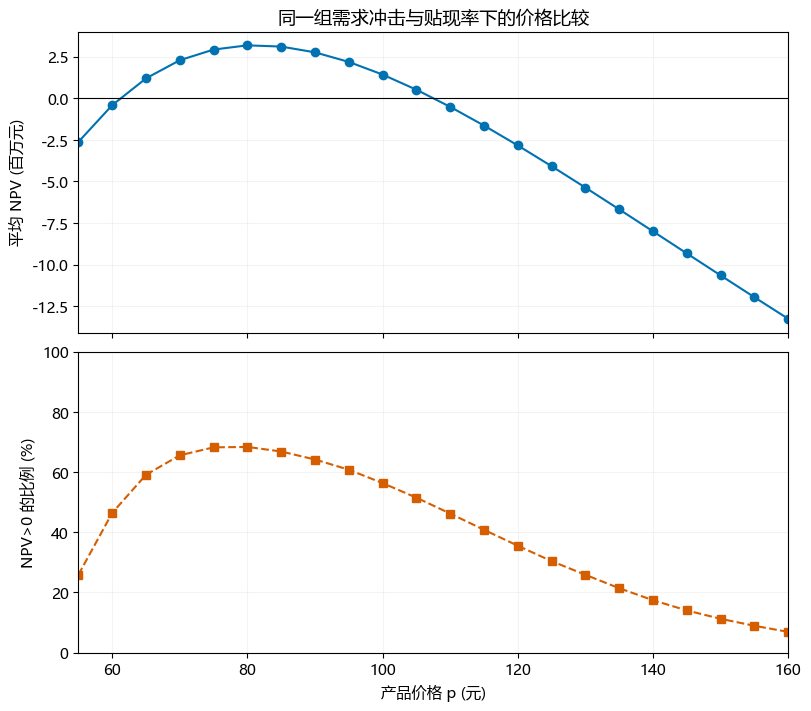

In [6]:
# PRICE_FIGURE
fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, layout='constrained')
axes[0].plot(price_results['price'], price_results['mean_npv_million'],
             marker='o', color='#0072B2')
axes[0].axhline(0, color='black', linewidth=.8)
axes[0].set(ylabel='平均 NPV (百万元)', title='同一组需求冲击与贴现率下的价格比较')
axes[1].plot(price_results['price'], price_results['prob_positive'] * 100,
             marker='s', linestyle='--', color='#D55E00')
axes[1].set(xlabel='产品价格 p (元)', ylabel='NPV>0 的比例 (%)', ylim=(0, 100))
for axis in axes:
    axis.grid(alpha=.15)
    axis.set_xlim(price_grid.min(), price_grid.max())
plt.show()


## NPV = 0 的决策边界

为了得到一条真正对应 10 年项目 NPV 的边界，先考虑一个简化情形：未来 10 年价格 $p$ 和市场份额 $s$ 保持不变，贴现率为 $r$。

此时：

$$
FCF=mpsQ_0-F.
$$

10 年年金现值因子为：

$$
A(r,T)=\sum_{t=1}^{T}\frac{1}{(1+r)^t}
=\frac{1-(1+r)^{-T}}{r}.
$$

令 $NPV=0$：

$$
-I_0+(mpsQ_0-F)A(r,T)=0.
$$

可得临界市场份额：

$$
s^*(p,r)
=
\frac{
F+I_0/A(r,T)
}{
mpQ_0
}.
$$

因此：

- 当 $s>s^*(p,r)$ 时，NPV 为正；
- 当 $s<s^*(p,r)$ 时，NPV 为负。

由于 $r$ 本身位于 $5\%$–$12\%$ 区间，NPV = 0 不再是一条唯一曲线，而形成一个由贴现率不确定性带来的边界带。


In [7]:

p_boundary = np.linspace(55, 160, 400)

s_low_r = required_share_for_npv_zero(p_boundary, r_min)
s_high_r = required_share_for_npv_zero(p_boundary, r_max)

# 贴现率均值对应的中心边界
mean_r = r_min + (r_max - r_min) * (a_r / (a_r + b_r))
s_mean_r = required_share_for_npv_zero(p_boundary, mean_r)

## 把模拟情景叠加到边界图上

市场份额逐年变化时，简单平均份额不能与逐年贴现的 NPV 精确对应。每个情景使用自己的贴现率计算

$$
\widetilde{s}(r)=\frac{\sum_{t=1}^{T}s_{t}(1+r)^{-t}}{A(r,T)}.
$$

在价格、年度市场规模、现金贡献比例和年度固定支出不变的条件下，

$$
NPV=mpQ_{0}A(r,T)\left[\widetilde{s}(r)-s^{*}(p,r)\right].
$$

前面的乘数为正，因此 NPV 的符号由加权份额与本情景临界份额之差决定。下图左侧每个价格只等概率选取 250 个情景用于展示，不按 NPV 正负挑点。两条曲线限定贴现率区间的临界份额带，不是置信区间。右侧使用 p=80 的全部 20000 个情景，直接对照份额差与 NPV。完整数值核对使用全部 22×20000 个价格—情景组合。

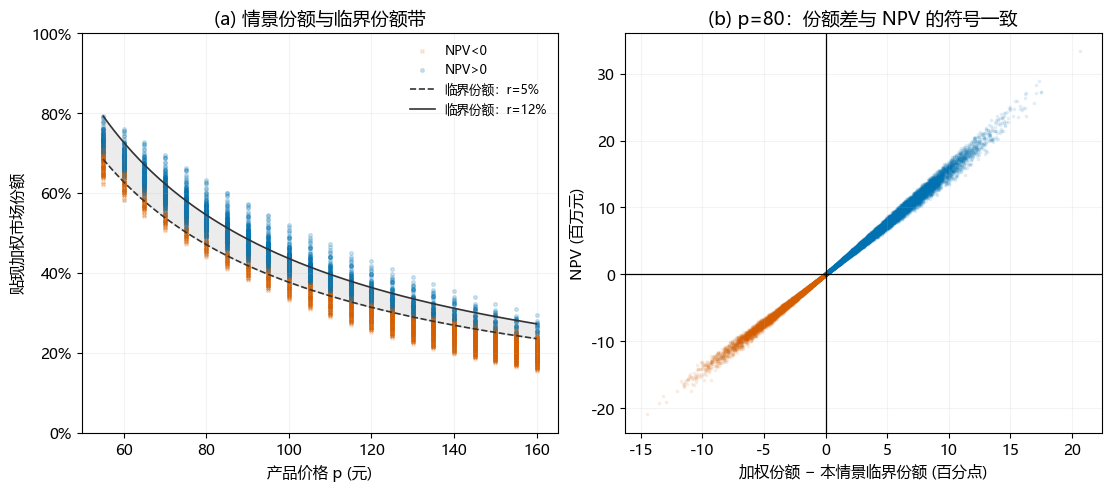

In [8]:
# WEIGHTED_BOUNDARY_FIGURE
from matplotlib.ticker import PercentFormatter
display_rng = np.random.default_rng(SEED + 98765)
display_indices = display_rng.choice(B, size=250, replace=False)
sample_rows = []
for price in price_grid:
    scenario = simulate_project(price, B=B, seed=SEED)
    sample_rows.append(pd.DataFrame({
        'price': price, 'weighted_share': scenario['weighted_share'][display_indices],
        'discount_rate': scenario['discount_rate'][display_indices],
        'npv': scenario['npv'][display_indices],
    }))
scatter_df = pd.concat(sample_rows, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), layout='constrained')
for positive, color, marker, label in [(False, '#D55E00', 'x', 'NPV<0'),
                                       (True, '#0072B2', 'o', 'NPV>0')]:
    selected = scatter_df['npv'] > 0 if positive else scatter_df['npv'] < 0
    axes[0].scatter(scatter_df.loc[selected, 'price'], scatter_df.loc[selected, 'weighted_share'],
                     color=color, marker=marker, s=7, alpha=.18, label=label)
axes[0].fill_between(p_boundary, s_low_r, s_high_r, color='.5', alpha=.15)
axes[0].plot(p_boundary, s_low_r, color='.2', linestyle='--', linewidth=1.2, label='临界份额：r=5%')
axes[0].plot(p_boundary, s_high_r, color='.2', linestyle='-', linewidth=1.2, label='临界份额：r=12%')
axes[0].set(xlabel='产品价格 p (元)', ylabel='贴现加权市场份额', ylim=(0, 1),
            title='(a) 情景份额与临界份额带')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(frameon=False, fontsize=9, loc='upper right')
critical_base = required_share_for_npv_zero(base_p, base['discount_rate'])
share_gap = base['weighted_share'] - critical_base
for positive, color in [(False, '#D55E00'), (True, '#0072B2')]:
    selected = base['npv'] > 0 if positive else base['npv'] < 0
    axes[1].scatter(share_gap[selected] * 100, base['npv'][selected] / 1e6,
                     s=3, alpha=.08, color=color)
axes[1].axvline(0, color='black', linewidth=.9)
axes[1].axhline(0, color='black', linewidth=.9)
axes[1].set(title='(b) p=80：份额差与 NPV 的符号一致',
            xlabel='加权份额 − 本情景临界份额 (百分点)', ylabel='NPV (百万元)')
for axis in axes:
    axis.grid(alpha=.15)
plt.show()


## 压力测试


In [9]:

def scenario_summary(name, **kwargs):
    result = simulate_project(base_p, **kwargs)
    return {
        "scenario": name,
        "mean_npv_million": result["npv"].mean() / 1e6,
        "prob_positive": np.mean(result["npv"] > 0),
        "npv_5pct_million": np.quantile(result["npv"], 0.05) / 1e6,
    }

stress_results = pd.DataFrame([
    scenario_summary("Baseline"),
    scenario_summary("Market size -15%", Q0=Q0 * 0.85),
    scenario_summary("Fixed cost +20%", F=F * 1.20),
    scenario_summary(
        "Higher discount rates",
        r_min=0.08,
        r_max=0.12,
        a_r=3.0,
        b_r=2.0,
    ),
])

stress_results


,scenario,mean_npv_million,prob_positive,npv_5pct_million
0,Baseline,3.188084,0.68365,-7.493066
1,Market size -15%,-8.591847,0.06120,-17.537460
2,Fixed cost +20%,-4.880873,0.22285,-15.381794
3,Higher discount rates,-0.665372,0.45135,-10.112402



## 模型诊断


In [10]:

diagnostics = pd.Series({
    "share_min": base["share"].min(),
    "share_max": base["share"].max(),
    "discount_rate_min": base["discount_rate"].min(),
    "discount_rate_max": base["discount_rate"].max(),
    "has_positive_npv": bool(np.any(base["npv"] > 0)),
    "has_negative_npv": bool(np.any(base["npv"] < 0)),
})
diagnostics


share_min            0.092589
share_max            0.921179
discount_rate_min    0.051174
discount_rate_max    0.117311
has_positive_npv         True
has_negative_npv         True
dtype: object

## 价格指标与边界恒等式的完整核验

检查 NPV 重构误差、符号一致性、门槛附近的正负号和简单平均份额反例。原始经营假设与抽样顺序不变。

In [11]:
"""价格决策指标与贴现加权市场份额的可执行核验。"""
from pathlib import Path
import json
import os

export_dir = Path(os.environ.get('FINECO_VALUATION_EXPORT', 'output/monte-carlo/valuation'))
export_dir.mkdir(parents=True, exist_ok=True)
years = np.arange(1, T + 1)
valuation_scenarios = {}
decision_rows = []
validation_rows = []
for price in price_grid:
    scenario = simulate_project(price)
    discount = (1 + scenario['discount_rate'][:, None]) ** (-years)
    annuity = discount.sum(axis=1)
    weighted_share = (scenario['share'] * discount).sum(axis=1) / annuity
    critical_share = (F + I0 / annuity) / (m * price * Q0)
    reconstructed_npv = -I0 + (m * price * Q0 * weighted_share - F) * annuity
    gap_npv = m * price * Q0 * annuity * (weighted_share - critical_share)
    original_npv = scenario['npv']
    direct_positive = original_npv > 0
    weighted_positive = weighted_share > critical_share
    arithmetic_positive = scenario['avg_share'] > critical_share
    identity_error = np.abs(original_npv - reconstructed_npv).max()
    assert np.allclose(original_npv, reconstructed_npv, rtol=1e-12, atol=1e-6)
    assert np.allclose(original_npv, gap_npv, rtol=1e-12, atol=1e-6)
    assert np.array_equal(direct_positive, weighted_positive)
    assert np.array_equal(annuity > 0, np.ones(B, dtype=bool))
    assert np.allclose(annuity, annuity_factor(scenario['discount_rate']), rtol=1e-13, atol=1e-13)
    assert np.allclose(critical_share, required_share_for_npv_zero(price, scenario['discount_rate']))
    low = required_share_for_npv_zero(price, r_min)
    high = required_share_for_npv_zero(price, r_max)
    assert low < high
    assert np.all(direct_positive[weighted_share > high])
    assert not np.any(direct_positive[weighted_share < low])
    valuation_scenarios[price] = {
        'npv': original_npv, 'weighted_share': weighted_share,
        'avg_share': scenario['avg_share'], 'critical_share': critical_share,
        'discount_rate': scenario['discount_rate'],
    }
    decision_rows.append({
        'price': price, 'mean_npv_million': original_npv.mean() / 1e6,
        'median_npv_million': np.median(original_npv) / 1e6,
        'prob_positive': direct_positive.mean(),
        'npv_5pct_million': np.quantile(original_npv, .05) / 1e6,
        'mean_mcse_million': original_npv.std(ddof=1) / np.sqrt(B) / 1e6,
        'mean_share': scenario['share'].mean(),
        'zero_npv_count': int((original_npv == 0).sum()),
    })
    validation_rows.append({
        'price': price, 'B': B, 'max_identity_error': identity_error,
        'weighted_sign_mismatches': int((direct_positive != weighted_positive).sum()),
        'arithmetic_sign_mismatches': int((direct_positive != arithmetic_positive).sum()),
    })

decision_results = pd.DataFrame(decision_rows)
weighted_checks = pd.DataFrame(validation_rows)
decision_results.to_csv(export_dir / 'price-results.csv', index=False, encoding='utf-8-sig')
weighted_checks.to_csv(export_dir / 'weighted-checks.csv', index=False, encoding='utf-8-sig')
summary.rename('value').to_csv(export_dir / 'baseline-summary.csv', encoding='utf-8-sig')
stress_results.to_csv(export_dir / 'stress-results.csv', index=False, encoding='utf-8-sig')
np.savez_compressed(export_dir / 'scenarios.npz', prices=price_grid,
    npv=np.stack([valuation_scenarios[price]['npv'] for price in price_grid]),
    weighted_share=np.stack([valuation_scenarios[price]['weighted_share'] for price in price_grid]),
    arithmetic_share=np.stack([valuation_scenarios[price]['avg_share'] for price in price_grid]),
    critical_share=np.stack([valuation_scenarios[price]['critical_share'] for price in price_grid]),
    discount_rate=np.stack([valuation_scenarios[price]['discount_rate'] for price in price_grid]))

# 构造简单平均完全相同、但较高份额出现时间不同的两条记录。
example_rate = .08
example_price = 80.
example_discount = (1 + example_rate) ** (-years)
examples = []
for name, shares in [('较高份额在前五年', np.r_[np.full(5, .8), np.full(5, .2)]),
                      ('较高份额在后五年', np.r_[np.full(5, .2), np.full(5, .8)])]:
    weighted = np.sum(shares * example_discount) / example_discount.sum()
    value = -I0 + np.sum((m * example_price * Q0 * shares - F) * example_discount)
    examples.append({'example': name, 'arithmetic_share': shares.mean(),
        'weighted_share': weighted, 'critical_share': required_share_for_npv_zero(example_price, example_rate),
        'npv_million': value / 1e6})
counterexample = pd.DataFrame(examples)
assert np.isclose(counterexample.arithmetic_share.iloc[0], counterexample.arithmetic_share.iloc[1])
assert counterexample.npv_million.iloc[0] > 0 and counterexample.npv_million.iloc[1] < 0
counterexample.to_csv(export_dir / 'same-average-counterexample.csv', index=False, encoding='utf-8-sig')

# 在门槛及两侧做确定性检查，舍入误差不作为 NPV=0 的经济偏差。
rates = np.linspace(r_min, r_max, 51)
annuity = np.sum((1 + rates[:, None]) ** (-years), axis=1)
required = (F + I0 / annuity) / (m * example_price * Q0)
zero_npv = -I0 + (m * example_price * Q0 * required - F) * annuity
assert np.max(np.abs(zero_npv)) < 1e-6
assert np.all(-I0 + (m * example_price * Q0 * (required + 1e-4) - F) * annuity > 0)
assert np.all(-I0 + (m * example_price * Q0 * (required - 1e-4) - F) * annuity < 0)
assert np.all(np.diff(required) > 0)
assert np.all(np.diff(required_share_for_npv_zero(price_grid, .08)) < 0)
assert required_share_for_npv_zero(30., .08) > 1

maxima = {}
for metric in ['mean_npv_million', 'prob_positive', 'npv_5pct_million']:
    row = decision_results.loc[decision_results[metric].idxmax()]
    maxima[metric] = {'price': float(row.price), 'value': float(row[metric])}
audit = {
    'price_count': len(price_grid), 'B': B, 'scenario_count': len(price_grid) * B,
    'weighted_sign_mismatches': int(weighted_checks.weighted_sign_mismatches.sum()),
    'arithmetic_sign_mismatches': int(weighted_checks.arithmetic_sign_mismatches.sum()),
    'max_identity_error': float(weighted_checks.max_identity_error.max()),
    'fixed_share_boundary_max_abs_npv': float(np.abs(zero_npv).max()),
    'grid_maxima': maxima, 'same_random_inputs_across_prices': bool(all(np.array_equal(
        valuation_scenarios[price_grid[0]]['discount_rate'], valuation_scenarios[price]['discount_rate']) for price in price_grid)),
}
(export_dir / 'weighted-audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
display(decision_results)
display(weighted_checks)
display(counterexample)
print(json.dumps(audit, ensure_ascii=False, indent=2))


,price,mean_npv_million,median_npv_million,prob_positive,npv_5pct_million,mean_mcse_million,mean_share,zero_npv_count
0,55,-2.619689,-2.620367,0.25885,-9.288763,0.028761,0.702153,0
1,60,-0.411728,-0.424316,0.46425,-8.002956,0.032810,0.663165,0
2,65,1.201970,1.180067,0.59120,-7.269648,0.036643,0.625320,0
3,70,2.294102,2.255193,0.65585,-6.984696,0.040216,0.588925,0
4,75,2.934453,2.886355,0.68225,-7.074938,0.043498,0.554185,0
5,80,3.188084,3.122746,0.68365,-7.493066,0.046471,0.521222,0
6,85,3.114320,3.024545,0.66845,-8.159387,0.049130,0.490092,0
7,90,2.766341,2.635134,0.64180,-8.994470,0.051478,0.460803,0
8,95,2.191171,2.014173,0.60790,-9.976331,0.053524,0.433329,0
9,100,1.429937,1.243946,0.56340,-11.085646,0.055282,0.407615,0


,price,B,max_identity_error,weighted_sign_mismatches,arithmetic_sign_mismatches
0,55,20000,4.470348e-08,0,870
1,60,20000,4.470348e-08,0,1275
2,65,20000,4.470348e-08,0,1312
3,70,20000,4.470348e-08,0,1241
4,75,20000,4.470348e-08,0,1214
5,80,20000,4.470348e-08,0,1238
6,85,20000,5.215406e-08,0,1257
7,90,20000,5.960464e-08,0,1299
8,95,20000,5.215406e-08,0,1287
9,100,20000,4.470348e-08,0,1358


,example,arithmetic_share,weighted_share,critical_share,npv_million
0,较高份额在前五年,0.5,0.557019,0.500716,8.462699
1,较高份额在后五年,0.5,0.442981,0.500716,-8.677853


{
  "price_count": 22,
  "B": 20000,
  "scenario_count": 440000,
  "weighted_sign_mismatches": 0,
  "arithmetic_sign_mismatches": 24268,
  "max_identity_error": 5.960464477539063e-08,
  "fixed_share_boundary_max_abs_npv": 1.4901161193847656e-08,
  "grid_maxima": {
    "mean_npv_million": {
      "price": 80.0,
      "value": 3.1880844668561434
    },
    "prob_positive": {
      "price": 80.0,
      "value": 0.68365
    },
    "npv_5pct_million": {
      "price": 70.0,
      "value": -6.984696376603105
    }
  },
  "same_random_inputs_across_prices": true
}


## 相邻价格和种子敏感性

最高的样本网格指标不等于现实中的唯一最优价格。以下检查只评估有限次模拟的数值波动，不替代经营模型的敏感性分析。

In [12]:
"""相同模型下的种子敏感性与相邻价格的配对 Monte Carlo 误差。"""
stability_rows = []
for comparison_seed in [SEED, SEED + 1, SEED + 2]:
    for price in price_grid:
        scenario = simulate_project(price, B=B, seed=comparison_seed)
        stability_rows.append({
            'seed': comparison_seed, 'price': price,
            'mean_npv_million': scenario['npv'].mean() / 1e6,
            'prob_positive': np.mean(scenario['npv'] > 0),
            'npv_5pct_million': np.quantile(scenario['npv'], .05) / 1e6,
        })
seed_comparison = pd.DataFrame(stability_rows)
seed_comparison.to_csv(export_dir / 'seed-comparison.csv', index=False, encoding='utf-8-sig')
peak_rows = []
for comparison_seed, group in seed_comparison.groupby('seed'):
    for metric in ['mean_npv_million', 'prob_positive', 'npv_5pct_million']:
        peak = group.loc[group[metric].idxmax()]
        peak_rows.append({'seed': comparison_seed, 'metric': metric,
                          'price': peak.price, 'value': peak[metric]})
seed_peaks = pd.DataFrame(peak_rows)
seed_peaks.to_csv(export_dir / 'seed-peaks.csv', index=False, encoding='utf-8-sig')
baseline_probability_difference = ((valuation_scenarios[80]['npv'] > 0).astype(float)
                                   - (valuation_scenarios[75]['npv'] > 0).astype(float))
paired_probability_check = pd.Series({
    'price_80_minus_75_probability_difference': baseline_probability_difference.mean(),
    'paired_MC_standard_error': baseline_probability_difference.std(ddof=1) / np.sqrt(B),
})
paired_probability_check.to_csv(export_dir / 'paired-probability-check.csv', encoding='utf-8-sig')
display(seed_peaks)
display(paired_probability_check)
print('以上检查反映有限次模拟的数值波动，不构成需求关系或项目价值的现实不确定性区间。')


,seed,metric,price,value
0,20261001,mean_npv_million,80.0,3.188084
1,20261001,prob_positive,80.0,0.683650
2,20261001,npv_5pct_million,70.0,-6.984696
3,20261002,mean_npv_million,80.0,3.144136
4,20261002,prob_positive,80.0,0.677550
5,20261002,npv_5pct_million,70.0,-7.036581
6,20261003,mean_npv_million,80.0,3.122301
7,20261003,prob_positive,80.0,0.675700
8,20261003,npv_5pct_million,70.0,-7.035482


price_80_minus_75_probability_difference    0.001400
paired_MC_standard_error                    0.000686
dtype: float64

以上检查反映有限次模拟的数值波动，不构成需求关系或项目价值的现实不确定性区间。


[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-valuation) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/02-project-valuation-monte-carlo.zip)

本 Notebook 从头执行并保存输出；网页渲染不执行代码。